## 1. Import Libraries

In [4]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.5
NumPy version: 2.5.2


In [6]:
import os

print(os.getcwd())

/Users/missie/sharks


In [7]:
# Load the three datasets
iccat = pd.read_csv("data/ICCAT.csv")
iotc = pd.read_csv("data/IOTC.csv")
iattc = pd.read_csv("data/IATTC.csv")

print("ICCAT:", iccat.shape)
print("IOTC:", iotc.shape)
print("IATTC:", iattc.shape)

ICCAT: (8592, 69)
IOTC: (13500, 61)
IATTC: (339300, 54)


## 2. Data Understanding

In [8]:
iccat.head()

,.pred_class,pres_abs,catch,rfmo,year,latitude,longitude,species_sciname,catch_units,gear_group,...,target_effort_st_vincent_and_grenadines_longline,target_effort_trinidad_and_tobago_longline,target_effort_uruguay_longline,target_effort_venezuela_longline,target_effort_turks_and_caicos_longline,target_effort_great_britain_longline,target_effort_cote_d_ivoire_longline,target_effort_cyprus_longline,.pred,.final_pred
0,1,present,1.0,ICCAT,2012,-50,-50,ISURUS OXYRINCHUS,count,longline,...,0.0,0.000000,0.000167,0.0,0.000168,0.000355,0.0,0.0,16.882809,16.882809
1,0,absent,0.0,ICCAT,2012,-50,-50,LAMNA NASUS,count,longline,...,0.0,0.000000,0.000167,0.0,0.000168,0.000355,0.0,0.0,101.533265,0.000000
2,1,present,3.0,ICCAT,2012,-50,-50,PRIONACE GLAUCA,count,longline,...,0.0,0.000000,0.000167,0.0,0.000168,0.000355,0.0,0.0,90.618127,90.618127
3,0,absent,0.0,ICCAT,2012,-50,-50,SHARKS NEI,count,longline,...,0.0,0.000000,0.000167,0.0,0.000168,0.000355,0.0,0.0,58.821324,0.000000
4,1,present,10.0,ICCAT,2012,-50,-45,ISURUS OXYRINCHUS,count,longline,...,0.0,0.000098,0.001639,0.0,0.000122,0.001362,0.0,0.0,22.640557,22.640557


In [9]:
iccat.info()

<class 'pandas.DataFrame'>
RangeIndex: 8592 entries, 0 to 8591
Data columns (total 69 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   .pred_class                                       8592 non-null   int64  
 1   pres_abs                                          8592 non-null   str    
 2   catch                                             8592 non-null   float64
 3   rfmo                                              8592 non-null   str    
 4   year                                              8592 non-null   int64  
 5   latitude                                          8592 non-null   int64  
 6   longitude                                         8592 non-null   int64  
 7   species_sciname                                   8592 non-null   str    
 8   catch_units                                       8592 non-null   str    
 9   gear_group                    

In [10]:
iccat.columns.tolist()

['.pred_class',
 'pres_abs',
 'catch',
 'rfmo',
 'year',
 'latitude',
 'longitude',
 'species_sciname',
 'catch_units',
 'gear_group',
 'spatial_notes',
 'original_effort',
 'species_commonname',
 'species_group',
 'species_resolution',
 'median_price_group',
 'median_price_species',
 'sdm',
 'zone',
 'location_cluster',
 'target_effort',
 'target_effort_belize_longline',
 'target_effort_china_longline',
 'target_effort_japan_longline',
 'target_effort_korea_longline',
 'target_effort_spain_longline',
 'target_effort_taipei_longline',
 'target_effort_united_states_of_america_longline',
 'target_effort_vanuatu_longline',
 'mean_sst',
 'median_sst',
 'min_sst',
 'max_sst',
 'sd_sst',
 'se_sst',
 'cv_sst',
 'mean_chla',
 'median_chla',
 'min_chla',
 'max_chla',
 'sd_chla',
 'se_chla',
 'cv_chla',
 'mean_ssh',
 'median_ssh',
 'min_ssh',
 'max_ssh',
 'sd_ssh',
 'se_ssh',
 'cv_ssh',
 'target_effort_barbados_longline',
 'target_effort_bermuda_longline',
 'target_effort_brazil_longline',
 'tar

### 2.1 Compare Dataset Structures

In [11]:
# Compare column names across the three datasets

iccat_cols = set(iccat.columns)
iotc_cols = set(iotc.columns)
iattc_cols = set(iattc.columns)

common_cols = iccat_cols & iotc_cols & iattc_cols

print("ICCAT columns:", len(iccat_cols))
print("IOTC columns:", len(iotc_cols))
print("IATTC columns:", len(iattc_cols))
print("Common columns:", len(common_cols))

ICCAT columns: 69
IOTC columns: 61
IATTC columns: 54
Common columns: 43


In [12]:
sorted(common_cols)

['.final_pred',
 '.pred',
 '.pred_class',
 'catch',
 'catch_units',
 'cv_chla',
 'cv_ssh',
 'cv_sst',
 'gear_group',
 'latitude',
 'location_cluster',
 'longitude',
 'max_chla',
 'max_ssh',
 'max_sst',
 'mean_chla',
 'mean_ssh',
 'mean_sst',
 'median_chla',
 'median_price_group',
 'median_price_species',
 'median_ssh',
 'median_sst',
 'min_chla',
 'min_ssh',
 'min_sst',
 'original_effort',
 'pres_abs',
 'rfmo',
 'sd_chla',
 'sd_ssh',
 'sd_sst',
 'sdm',
 'se_chla',
 'se_ssh',
 'se_sst',
 'spatial_notes',
 'species_commonname',
 'species_group',
 'species_resolution',
 'species_sciname',
 'year',
 'zone']

In [13]:
print("Only in ICCAT:")
print(sorted(iccat_cols - iotc_cols - iattc_cols))

print("\nOnly in IOTC:")
print(sorted(iotc_cols - iccat_cols - iattc_cols))

print("\nOnly in IATTC:")
print(sorted(iattc_cols - iccat_cols - iotc_cols))

Only in ICCAT:
['target_effort_barbados_longline', 'target_effort_bermuda_longline', 'target_effort_brazil_longline', 'target_effort_canada_longline', 'target_effort_cote_d_ivoire_longline', 'target_effort_cyprus_longline', 'target_effort_great_britain_longline', 'target_effort_malta_longline', 'target_effort_maroc_longline', 'target_effort_mexico_longline', 'target_effort_namibia_longline', 'target_effort_philippines_longline', 'target_effort_st_vincent_and_grenadines_longline', 'target_effort_trinidad_and_tobago_longline', 'target_effort_turks_and_caicos_longline', 'target_effort_uruguay_longline', 'target_effort_venezuela_longline']

Only in IOTC:
['bycatch_total_effort', 'bycatch_total_effort_australia_longline', 'bycatch_total_effort_china_longline', 'bycatch_total_effort_france_longline', 'bycatch_total_effort_india_longline', 'bycatch_total_effort_indonesia_longline', 'bycatch_total_effort_japan_longline', 'bycatch_total_effort_kenya_longline', 'bycatch_total_effort_korea_longli

In [14]:
key_columns = [
    ".pred_class",
    "pres_abs",
    "catch",
    "rfmo",
    "year",
    "latitude",
    "longitude",
    "species_sciname",
    "species_commonname",
    "median_price_group",
    "median_price_species",
    "sdm",
    "zone",
    "location_cluster",
    ".pred",
    ".final_pred"
]

iccat[key_columns].head(10)

,.pred_class,pres_abs,catch,rfmo,year,latitude,longitude,species_sciname,species_commonname,median_price_group,median_price_species,sdm,zone,location_cluster,.pred,.final_pred
0,1,present,1.0,ICCAT,2012,-50,-50,ISURUS OXYRINCHUS,SHORTFIN MAKO SHARK,1808.653923,1187.262014,0.000000,-50|-50,1,16.882809,16.882809
1,0,absent,0.0,ICCAT,2012,-50,-50,LAMNA NASUS,PORBEAGLE SHARK,1808.653923,526.397823,1.000000,-50|-50,1,101.533265,0.000000
2,1,present,3.0,ICCAT,2012,-50,-50,PRIONACE GLAUCA,BLUE SHARK,1808.653923,1187.262014,0.000000,-50|-50,1,90.618127,90.618127
3,0,absent,0.0,ICCAT,2012,-50,-50,SHARKS NEI,SHARKS NEI,1808.653923,1808.653923,0.008399,-50|-50,1,58.821324,0.000000
4,1,present,10.0,ICCAT,2012,-50,-45,ISURUS OXYRINCHUS,SHORTFIN MAKO SHARK,1808.653923,1187.262014,0.000000,-50|-45,1,22.640557,22.640557
5,0,absent,0.0,ICCAT,2012,-50,-45,LAMNA NASUS,PORBEAGLE SHARK,1808.653923,526.397823,1.000000,-50|-45,1,99.171455,0.000000
6,1,present,10.0,ICCAT,2012,-50,-45,PRIONACE GLAUCA,BLUE SHARK,1808.653923,1187.262014,0.000000,-50|-45,1,104.523151,104.523151
7,0,absent,0.0,ICCAT,2012,-50,-45,SHARKS NEI,SHARKS NEI,1808.653923,1808.653923,0.007117,-50|-45,1,55.320851,0.000000
8,0,absent,0.0,ICCAT,2012,-50,-30,ISURUS OXYRINCHUS,SHORTFIN MAKO SHARK,1808.653923,1187.262014,0.000000,-50|-30,1,20.467465,0.000000
9,0,absent,0.0,ICCAT,2012,-50,-30,LAMNA NASUS,PORBEAGLE SHARK,1808.653923,526.397823,1.000000,-50|-30,1,107.325468,0.000000


In [15]:
# Create a column comparison table

all_cols = sorted(iccat_cols | iotc_cols | iattc_cols)

column_comparison = pd.DataFrame({
    "Column": all_cols,
    "ICCAT": [col in iccat_cols for col in all_cols],
    "IOTC": [col in iotc_cols for col in all_cols],
    "IATTC": [col in iattc_cols for col in all_cols]
})

column_comparison

,Column,ICCAT,IOTC,IATTC
0,.final_pred,True,True,True
1,.pred,True,True,True
2,.pred_class,True,True,True
3,bycatch_total_effort,False,True,False
4,bycatch_total_effort_australia_longline,False,True,False
...,...,...,...,...
84,target_effort_uruguay_longline,True,False,False
85,target_effort_vanuatu_longline,True,False,True
86,target_effort_venezuela_longline,True,False,False
87,year,True,True,True


## 3. Data Quality Assessment

### 3.1 Check Missing Values and Data Completeness

In [16]:
def missing_summary(df):
    summary = pd.DataFrame({
        "Missing_Count": df.isna().sum(),
        "Missing_Percent": (df.isna().mean() * 100).round(2)
    })
    
    return summary.sort_values(
        by="Missing_Percent",
        ascending=False
    )


iccat_missing = missing_summary(iccat)
iotc_missing = missing_summary(iotc)
iattc_missing = missing_summary(iattc)

In [17]:
iccat_missing[iccat_missing["Missing_Count"] > 0]

,Missing_Count,Missing_Percent
sd_chla,440,5.12
se_chla,440,5.12
cv_chla,440,5.12
min_chla,356,4.14
max_chla,356,4.14
median_chla,356,4.14
mean_chla,356,4.14
cv_sst,248,2.89
sd_sst,248,2.89
max_sst,248,2.89


In [18]:
iotc_missing[iotc_missing["Missing_Count"] > 0]

,Missing_Count,Missing_Percent
sd_chla,468,3.47
cv_chla,468,3.47
se_chla,468,3.47
max_chla,396,2.93
min_chla,396,2.93
median_chla,396,2.93
mean_chla,396,2.93
cv_ssh,234,1.73
mean_ssh,234,1.73
median_ssh,234,1.73


In [19]:
iattc_missing[iattc_missing["Missing_Count"] > 0]

,Missing_Count,Missing_Percent
se_chla,339300,100.00
cv_chla,339300,100.00
sd_chla,339300,100.00
mean_chla,27684,8.16
median_chla,27684,8.16
min_chla,27684,8.16
max_chla,27684,8.16
mean_sst,2205,0.65
cv_sst,2205,0.65
se_sst,2205,0.65


In [20]:
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():
    
    empty_cols = df.columns[df.isna().all()].tolist()
    print(f"{name}: {empty_cols}")

ICCAT: []
IOTC: []
IATTC: ['sd_chla', 'se_chla', 'cv_chla']


### 3.2 Duplicate and Consistency Checks

In [21]:
# Check exact duplicate rows

for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():
    
    duplicate_count = df.duplicated().sum()
    duplicate_percent = duplicate_count / len(df) * 100
    
    print(
        f"{name}: {duplicate_count} duplicates "
        f"({duplicate_percent:.2f}%)"
    )

ICCAT: 0 duplicates (0.00%)
IOTC: 0 duplicates (0.00%)
IATTC: 0 duplicates (0.00%)


In [22]:
key_cols = [
    "rfmo",
    "year",
    "latitude",
    "longitude",
    "species_sciname"
]

for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():
    
    duplicate_keys = df.duplicated(
        subset=key_cols,
        keep=False
    ).sum()
    
    print(f"{name}: {duplicate_keys} rows with duplicated keys")

ICCAT: 0 rows with duplicated keys
IOTC: 0 rows with duplicated keys
IATTC: 0 rows with duplicated keys


In [23]:
# Check Target consistency
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():
    
    print(f"\n{name}")
    
    print(
        pd.crosstab(
            df["catch"] > 0,
            df["pres_abs"]
        )
    )


ICCAT
pres_abs  absent  present
catch                    
False       5147        0
True           0     3445

IOTC
pres_abs  absent  present
catch                    
False       9528        0
True           0     3972

IATTC
pres_abs  absent  present
catch                    
False     262450        0
True           0    76850


### 3.3 Validity and Range Checks

In [24]:
# Check Target and Coordinates
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():

    print(f"\n{name}")
    print("Negative catch:", (df["catch"] < 0).sum())
    print("Invalid latitude:", ((df["latitude"] < -90) | (df["latitude"] > 90)).sum())
    print("Invalid longitude:", ((df["longitude"] < -180) | (df["longitude"] > 180)).sum())
    
    print("Year range:", df["year"].min(), "-", df["year"].max())
    print("Catch range:", df["catch"].min(), "-", df["catch"].max())


ICCAT
Negative catch: 0
Invalid latitude: 0
Invalid longitude: 0
Year range: 2012 - 2020
Catch range: 0.0 - 24153.5555555556

IOTC
Negative catch: 0
Invalid latitude: 0
Invalid longitude: 0
Year range: 2012 - 2020
Catch range: 0.0 - 13740.0

IATTC
Negative catch: 0
Invalid latitude: 0
Invalid longitude: 0
Year range: 2012 - 2020
Catch range: 0.0 - 1424.33713557703


In [25]:
# Envrionment Variables
environmental_cols = [
    "mean_sst",
    "mean_chla",
    "mean_ssh"
]

for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():

    print(f"\n{name}")
    print(df[environmental_cols].describe())


ICCAT
          mean_sst    mean_chla     mean_ssh
count  8344.000000  8236.000000  8348.000000
mean     22.409346     0.320414     0.035066
std       5.229165     1.104695     0.022744
min       0.000000     0.000000     0.000000
25%      19.612739     0.080631     0.020382
50%      23.599658     0.152054     0.032086
75%      26.625856     0.245634     0.046289
max      29.466100    16.556769     0.173512

IOTC
           mean_sst     mean_chla      mean_ssh
count  13293.000000  13104.000000  13266.000000
mean      22.947991      0.168955      0.041345
std        5.916171      0.502880      0.031547
min        0.270316      0.000000      0.000000
25%       18.369505      0.063748      0.018323
50%       25.245673      0.115698      0.037894
75%       27.783694      0.214947      0.058766
max       29.600463     13.373084      0.220563

IATTC
            mean_sst      mean_chla       mean_ssh
count  337095.000000  311616.000000  337752.000000
mean       23.659283       0.111342      

In [26]:
# Catch Distribution
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():

    print(f"\n{name} - Catch Distribution")
    print(df["catch"].describe())


ICCAT - Catch Distribution
count     8592.000000
mean       329.606511
std       1425.345201
min          0.000000
25%          0.000000
50%          0.000000
75%         35.166667
max      24153.555556
Name: catch, dtype: float64

IOTC - Catch Distribution
count    13500.000000
mean        96.504806
std        453.756459
min          0.000000
25%          0.000000
50%          0.000000
75%          4.000000
max      13740.000000
Name: catch, dtype: float64

IATTC - Catch Distribution
count    339300.000000
mean          5.745537
std          34.506735
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max        1424.337136
Name: catch, dtype: float64


In [27]:
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():

    positive_catch = df.loc[df["catch"] > 0, "catch"]

    print(f"\n{name} - Positive Catch Only")
    print(positive_catch.describe())


ICCAT - Positive Catch Only
count     3445.000000
mean       822.054903
std       2159.369615
min          0.027778
25%         13.000000
50%         80.000000
75%        506.341131
max      24153.555556
Name: catch, dtype: float64

IOTC - Positive Catch Only
count     3972.000000
mean       327.999718
std        789.917032
min          1.000000
25%         10.000000
50%         55.000000
75%        258.000000
max      13740.000000
Name: catch, dtype: float64

IATTC - Positive Catch Only
count    76850.000000
mean        25.367089
std         68.988570
min          0.022222
25%          0.545108
50%          2.942222
75%         19.240000
max       1424.337136
Name: catch, dtype: float64


In [28]:
# Species
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():

    print(f"\n{name}")
    print(df["species_commonname"].value_counts())


ICCAT
species_commonname
SHORTFIN MAKO SHARK    2148
PORBEAGLE SHARK        2148
BLUE SHARK             2148
SHARKS NEI             2148
Name: count, dtype: int64

IOTC
species_commonname
BLUE SHARK                        1500
MACKEREL SHARKS,PORBEAGLES NEI    1500
PORBEAGLE SHARK                   1500
SHARKS NEI                        1500
SILKY SHARK                       1500
OCEANIC WHITETIP SHARK            1500
HAMMERHEAD SHARKS NEI             1500
THRESHER SHARKS NEI               1500
REQUIEM SHARKS NEI                1500
Name: count, dtype: int64

IATTC
species_commonname
THRESHER SHARKS NEI      37700
REQUIEM SHARKS NEI       37700
SILKY SHARK              37700
BLACKTIP SHARK           37700
MAKO SHARKS              37700
SHORTFIN MAKO SHARK      37700
BLUE SHARK               37700
SHARKS NEI               37700
HAMMERHEAD SHARKS NEI    37700
Name: count, dtype: int64


### 3.4 Catch Unit Check

In [29]:
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():

    print(f"\n{name} - Catch Units")
    print(df["catch_units"].value_counts(dropna=False))


ICCAT - Catch Units
catch_units
count    8592
Name: count, dtype: int64

IOTC - Catch Units
catch_units
count    13500
Name: count, dtype: int64

IATTC - Catch Units
catch_units
count    339300
Name: count, dtype: int64


In [30]:
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():

    print(f"\n{name} - Species Groups")
    print(df["species_group"].value_counts(dropna=False))


ICCAT - Species Groups
species_group
sharks and rays    8592
Name: count, dtype: int64

IOTC - Species Groups
species_group
sharks and rays    13500
Name: count, dtype: int64

IATTC - Species Groups
species_group
sharks and rays    339300
Name: count, dtype: int64


In [31]:
species_sets = {
    "ICCAT": set(iccat["species_commonname"].unique()),
    "IOTC": set(iotc["species_commonname"].unique()),
    "IATTC": set(iattc["species_commonname"].unique())
}

common_species = (
    species_sets["ICCAT"]
    & species_sets["IOTC"]
    & species_sets["IATTC"]
)

print("Species common to all three RFMOs:")
print(sorted(common_species))

print("\nNumber of common species:", len(common_species))

Species common to all three RFMOs:
['BLUE SHARK', 'SHARKS NEI']

Number of common species: 2


In [32]:
for name, species in species_sets.items():
    print(name, ":", len(species), "species/categories")

ICCAT : 4 species/categories
IOTC : 9 species/categories
IATTC : 9 species/categories


In [33]:
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():
    
    print(f"\n{name}")
    print(df["catch_units"].unique())


ICCAT
<StringArray>
['count']
Length: 1, dtype: str

IOTC
<StringArray>
['count']
Length: 1, dtype: str

IATTC
<StringArray>
['count']
Length: 1, dtype: str


No duplicate records or invalid spatial coordinates were identified. Catch values were non-negative across all three datasets. Missingness was mainly concentrated in environmental variables and was generally low, except for chlorophyll variability measures in IATTC, which were entirely missing. Catch observations were strongly zero-inflated and right-skewed. The datasets covered 2012–2020 and contained different shark species compositions across RFMOs.

### 3.5 Target Distribution Check

In [34]:
# Zero Catch Percentage
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():
    
    zero_count = (df["catch"] == 0).sum()
    zero_percent = zero_count / len(df) * 100
    
    print(
        f"{name}: {zero_count} zero-catch observations "
        f"({zero_percent:.2f}%)"
    )

ICCAT: 5147 zero-catch observations (59.90%)
IOTC: 9528 zero-catch observations (70.58%)
IATTC: 262450 zero-catch observations (77.35%)


### 3.6. Feature Audit 

In [35]:
candidate_features = [
    "catch",
    "mean_sst",
    "mean_chla",
    "mean_ssh",
    "original_effort",
    "bycatch_total_effort",
    "year",
    "latitude",
    "longitude",
    "species_commonname",
    "rfmo"
]

datasets = {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}

for name, df in datasets.items():
    print(f"\n{'='*15} {name} {'='*15}")

    for col in candidate_features:
        if col in df.columns:
            missing = df[col].isna().sum()
            missing_pct = missing / len(df) * 100
            unique = df[col].nunique(dropna=True)

            print(
                f"{col:<25} "
                f"missing={missing:<8} "
                f"({missing_pct:6.2f}%) "
                f"unique={unique}"
            )
        else:
            print(f"{col:<25} NOT AVAILABLE")


=============== ICCAT ===============
catch                     missing=0        (  0.00%) unique=2714
mean_sst                  missing=248      (  2.89%) unique=2086
mean_chla                 missing=356      (  4.14%) unique=2053
mean_ssh                  missing=244      (  2.84%) unique=1972
original_effort           missing=0        (  0.00%) unique=2094
bycatch_total_effort      NOT AVAILABLE
year                      missing=0        (  0.00%) unique=9
latitude                  missing=0        (  0.00%) unique=24
longitude                 missing=0        (  0.00%) unique=26
species_commonname        missing=0        (  0.00%) unique=4
rfmo                      missing=0        (  0.00%) unique=1

=============== IOTC ===============
catch                     missing=0        (  0.00%) unique=1056
mean_sst                  missing=207      (  1.53%) unique=1477
mean_chla                 missing=396      (  2.93%) unique=1452
mean_ssh                  missing=234      (  1.73%

In [36]:
cols_to_check = [
    "catch",
    "mean_sst",
    "mean_chla",
    "mean_ssh",
    "original_effort",
    "bycatch_total_effort"
]

for col in cols_to_check:
    if col in iattc.columns:
        print(
            f"{col:<25} "
            f"missing={iattc[col].isna().sum():<8} "
            f"({iattc[col].isna().mean()*100:6.2f}%) "
            f"unique={iattc[col].nunique()}"
        )
    else:
        print(f"{col:<25} NOT AVAILABLE")

catch                     missing=0        (  0.00%) unique=2236
mean_sst                  missing=2205     (  0.65%) unique=37455
mean_chla                 missing=27684    (  8.16%) unique=34585
mean_ssh                  missing=1548     (  0.46%) unique=30768
original_effort           missing=0        (  0.00%) unique=1471
bycatch_total_effort      NOT AVAILABLE


### 3.7 Summary

In [37]:
# Data quality summary for key modelling variables

datasets = {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}

summary = []

for name, df in datasets.items():
    summary.append({
        "Dataset": name,
        "SST Missing (%)": df["mean_sst"].isna().mean() * 100,
        "Chlorophyll-a Missing (%)": df["mean_chla"].isna().mean() * 100,
        "SSH Missing (%)": df["mean_ssh"].isna().mean() * 100,
        "Zero Catch (%)": (df["catch"] == 0).mean() * 100
    })

quality_summary = pd.DataFrame(summary)

# Round percentages to 2 decimal places
quality_summary = quality_summary.round(2)

quality_summary

,Dataset,SST Missing (%),Chlorophyll-a Missing (%),SSH Missing (%),Zero Catch (%)
0,ICCAT,2.89,4.14,2.84,59.90
1,IOTC,1.53,2.93,1.73,70.58
2,IATTC,0.65,8.16,0.46,77.35


## 4. Exploratory Data Analysis

### 4.1 Spatial Distribution of Observations

In [38]:
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():

    print(f"\n{name}")
    print("Latitude:", df["latitude"].min(), "to", df["latitude"].max())
    print("Longitude:", df["longitude"].min(), "to", df["longitude"].max())


ICCAT
Latitude: -55 to 60
Longitude: -95 to 30

IOTC
Latitude: -57.5 to 27.5
Longitude: 20 to 145

IATTC
Latitude: -44.5 to 44.5
Longitude: -149.5 to -70.5


### 4.2 Spatial Coverage by RFMO

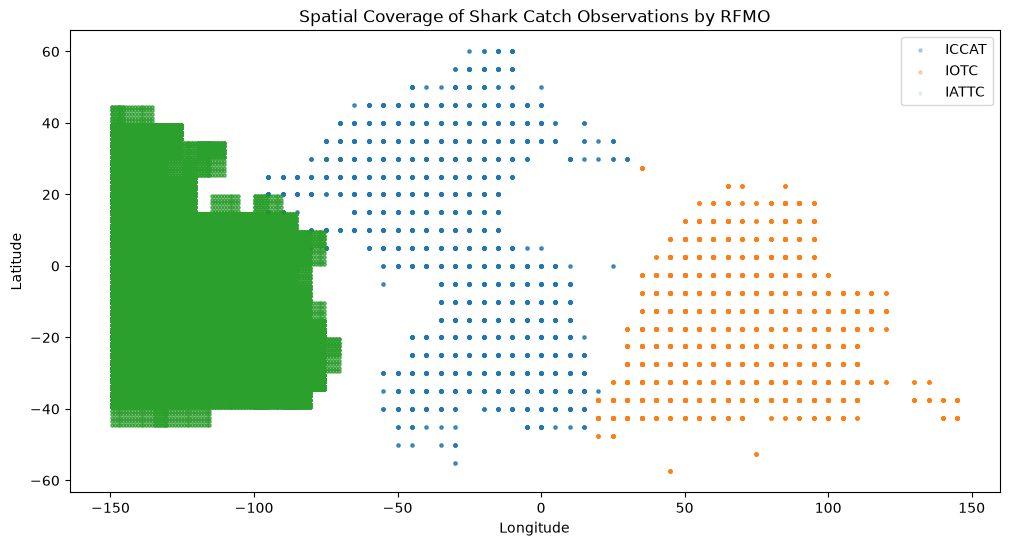

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.scatter(
    iccat["longitude"],
    iccat["latitude"],
    s=5,
    alpha=0.3,
    label="ICCAT"
)

plt.scatter(
    iotc["longitude"],
    iotc["latitude"],
    s=5,
    alpha=0.3,
    label="IOTC"
)

plt.scatter(
    iattc["longitude"],
    iattc["latitude"],
    s=5,
    alpha=0.1,
    label="IATTC"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Coverage of Shark Catch Observations by RFMO")
plt.legend()

plt.show()

In [40]:
for name, df in {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}.items():

    lat_values = sorted(df["latitude"].unique())
    lon_values = sorted(df["longitude"].unique())

    lat_diff = pd.Series(lat_values).diff().dropna()
    lon_diff = pd.Series(lon_values).diff().dropna()

    print(f"\n{name}")
    print("Unique latitudes:", len(lat_values))
    print("Unique longitudes:", len(lon_values))
    print("Minimum latitude spacing:", lat_diff.min())
    print("Minimum longitude spacing:", lon_diff.min())


ICCAT
Unique latitudes: 24
Unique longitudes: 26
Minimum latitude spacing: 5.0
Minimum longitude spacing: 5.0

IOTC
Unique latitudes: 18
Unique longitudes: 25
Minimum latitude spacing: 5.0
Minimum longitude spacing: 5.0

IATTC
Unique latitudes: 90
Unique longitudes: 80
Minimum latitude spacing: 1.0
Minimum longitude spacing: 1.0


### Spatial Resolution

The three RFMO datasets use different spatial resolutions. ICCAT and IOTC observations are recorded on approximately 5° × 5° spatial grids, while IATTC observations use a finer 1° × 1° grid. This difference partly explains the substantially larger number of observations in the IATTC dataset and should be considered when combining the datasets for modelling.

### 4.3 Temporal Coverage

In [41]:
year_counts = pd.DataFrame({
    "ICCAT": iccat["year"].value_counts().sort_index(),
    "IOTC": iotc["year"].value_counts().sort_index(),
    "IATTC": iattc["year"].value_counts().sort_index()
})

year_counts

,ICCAT,IOTC,IATTC
year,,,
2012,1008,1512,37125
2013,948,1458,40725
2014,940,1449,37575
2015,1004,1512,35550
2016,972,1422,37350
2017,964,1467,38250
2018,924,1620,39600
2019,900,1512,35550
2020,932,1548,37575


### Temporal Coverage

All three RFMO datasets cover the full period from 2012 to 2020. 
The number of observations varies moderately between years, but no year is 
completely missing and no major temporal gaps are evident. IATTC consistently 
contains substantially more observations because of its finer spatial resolution.

### 4.4 Shark Catch Distribution   

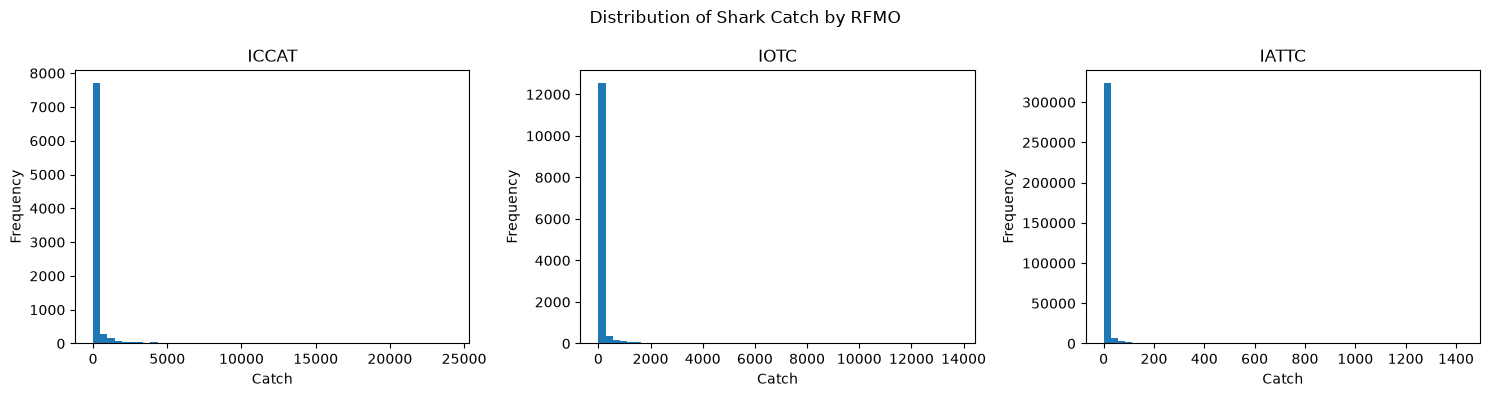

In [42]:
# Catch distribution across the three RFMO datasets

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

datasets = {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}

for ax, (name, df) in zip(axes, datasets.items()):
    ax.hist(df["catch"], bins=50)
    ax.set_title(name)
    ax.set_xlabel("Catch")
    ax.set_ylabel("Frequency")

plt.suptitle("Distribution of Shark Catch by RFMO")
plt.tight_layout()
plt.show()

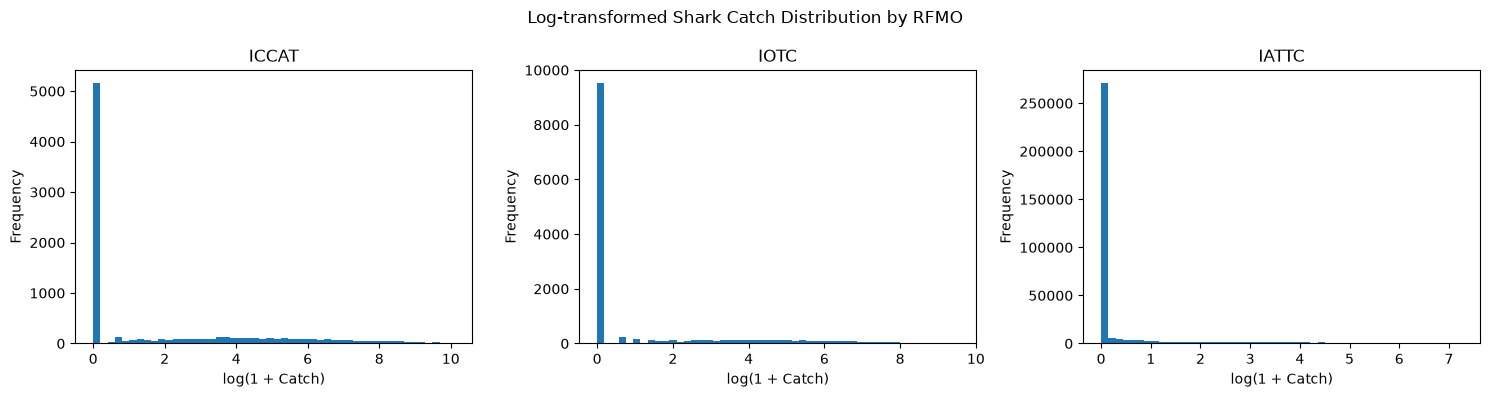

In [43]:
# Log-transformed catch distribution

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, df) in zip(axes, datasets.items()):
    log_catch = np.log1p(df["catch"])

    ax.hist(log_catch, bins=50)
    ax.set_title(name)
    ax.set_xlabel("log(1 + Catch)")
    ax.set_ylabel("Frequency")

plt.suptitle("Log-transformed Shark Catch Distribution by RFMO")
plt.tight_layout()
plt.show()

Shark Catch Distribution

Catch values are highly right-skewed across all three RFMO datasets, with most observations concentrated at zero or relatively low catch levels and a smaller number of observations containing substantially higher catches. A log transformation reduces the influence of extreme catch values and provides a clearer view of the non-zero catch distribution. However, a large concentration at zero remains, particularly in the IATTC dataset. This zero-heavy and skewed target distribution should be considered during subsequent modelling.

### 4.5 Catch by Species

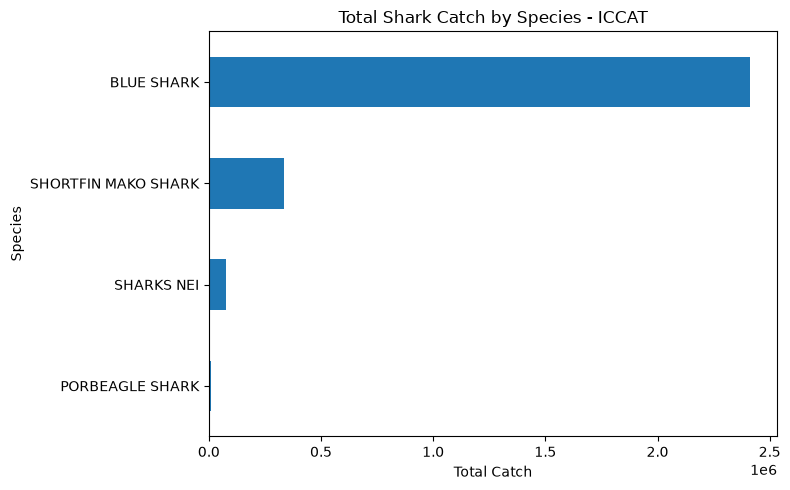

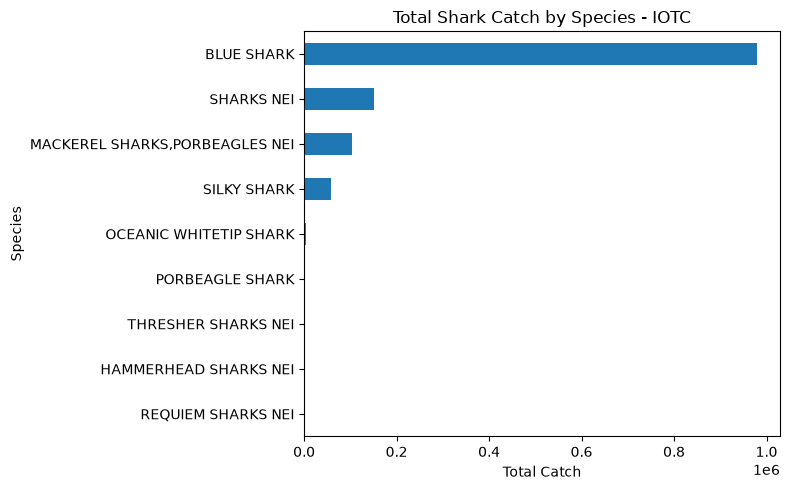

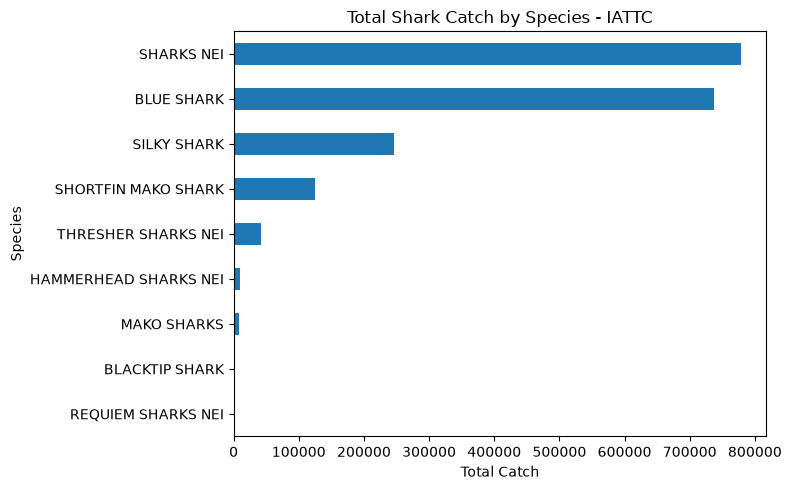

In [44]:
# Total catch by species for each RFMO

for name, df in datasets.items():

    species_catch = (
        df.groupby("species_commonname")["catch"]
        .sum()
        .sort_values(ascending=True)
    )

    plt.figure(figsize=(8, 5))

    species_catch.plot(kind="barh")

    plt.title(f"Total Shark Catch by Species - {name}")
    plt.xlabel("Total Catch")
    plt.ylabel("Species")

    plt.tight_layout()
    plt.show()

### Catch by Species

Shark catch composition differs substantially among the three RFMO datasets. Blue Shark dominates the recorded catch in ICCAT and IOTC, while the IATTC dataset contains large catches classified as SHARKS NEI as well as Blue Shark. Other species, including Shortfin Mako Shark and Silky Shark, contribute smaller but regionally important catches.

These results represent recorded fisheries catch rather than natural shark abundance. Differences among RFMOs may therefore reflect not only species distribution but also fishing activity, reporting practices, species classification and spatial coverage.

### 4.6 Environmental Variables vs Catch

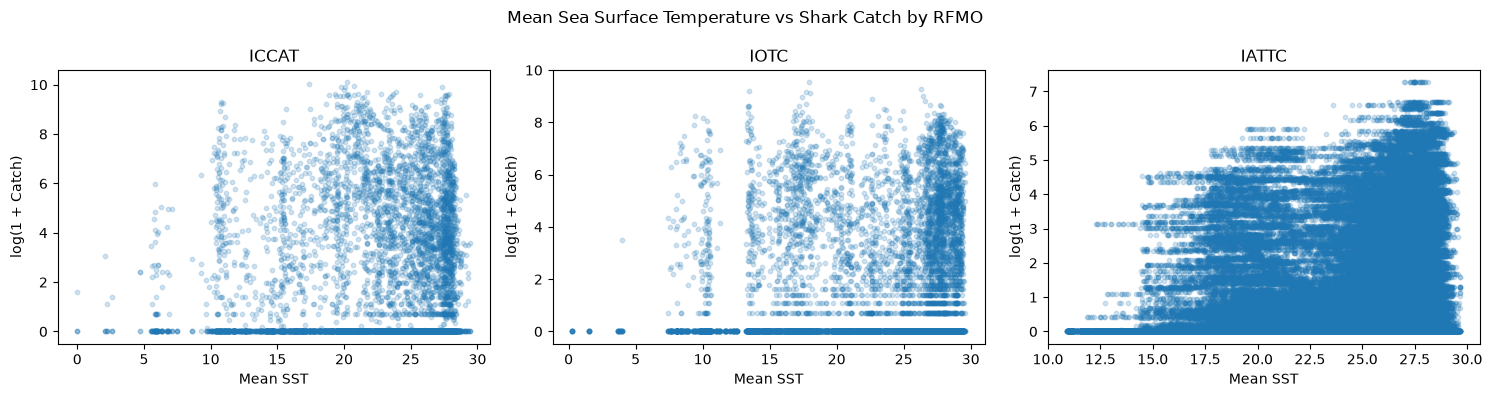

In [45]:
# Mean SST vs Shark Catch

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, df) in zip(axes, datasets.items()):

    ax.scatter(
        df["mean_sst"],
        np.log1p(df["catch"]),
        alpha=0.2,
        s=10
    )

    ax.set_title(name)
    ax.set_xlabel("Mean SST")
    ax.set_ylabel("log(1 + Catch)")

plt.suptitle("Mean Sea Surface Temperature vs Shark Catch by RFMO")
plt.tight_layout()
plt.show()

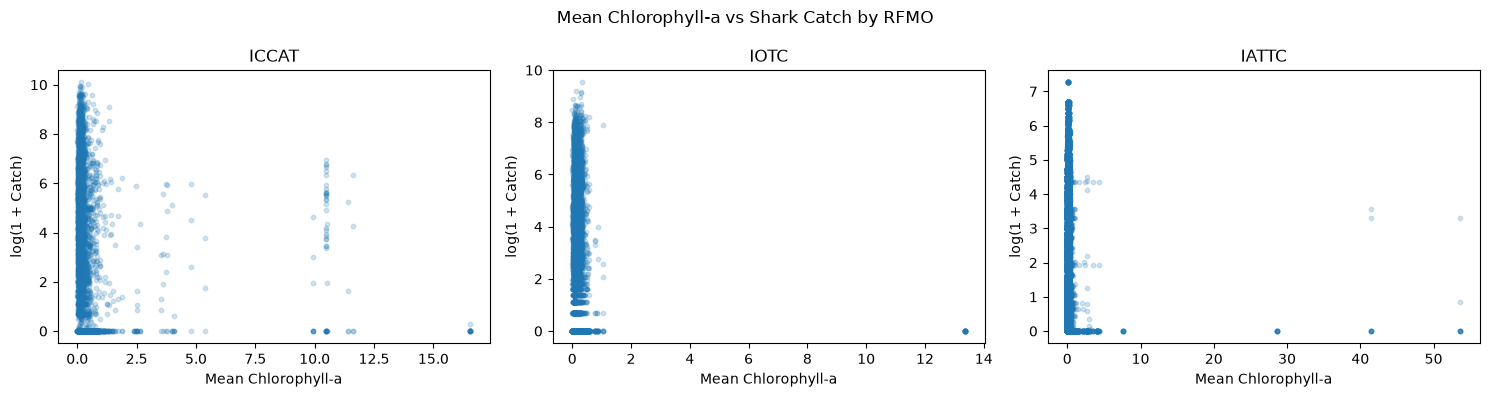

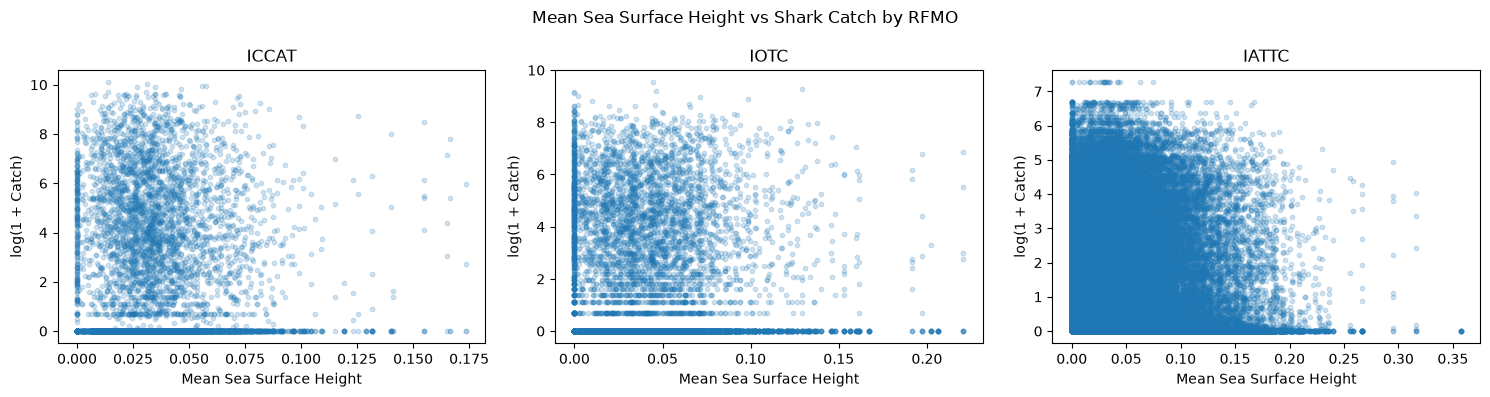

In [46]:
# Chlorophyll-a and SSH vs Shark Catch

environmental_vars = {
    "mean_chla": "Mean Chlorophyll-a",
    "mean_ssh": "Mean Sea Surface Height"
}

for variable, label in environmental_vars.items():

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, (name, df) in zip(axes, datasets.items()):

        ax.scatter(
            df[variable],
            np.log1p(df["catch"]),
            alpha=0.2,
            s=10
        )

        ax.set_title(name)
        ax.set_xlabel(label)
        ax.set_ylabel("log(1 + Catch)")

    plt.suptitle(f"{label} vs Shark Catch by RFMO")
    plt.tight_layout()
    plt.show()

### Environmental Variables vs Catch

The relationships between environmental variables and shark catch differ across the three RFMOs. SST shows the clearest visual pattern, particularly in the IATTC dataset, although substantial variation in catch remains at similar temperatures. Chlorophyll-a does not show a clear relationship with catch and contains several extreme values. SSH shows some potential non-linear patterns, but no strong linear relationship is evident.

Overall, the exploratory results suggest that shark catch cannot be explained by a single environmental variable. The relationships appear complex and potentially non-linear, supporting the use of multiple predictors in the subsequent modelling stage.

### 4.7 Fishing Effort vs Catch

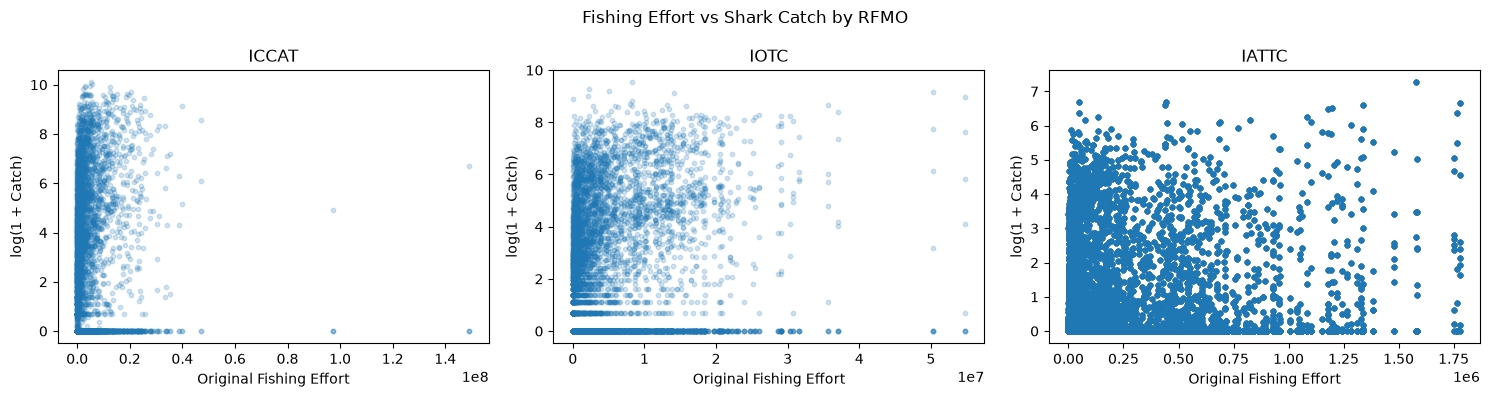

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, df) in zip(axes, datasets.items()):

    ax.scatter(
        df["original_effort"],
        np.log1p(df["catch"]),
        alpha=0.2,
        s=10
    )

    ax.set_title(name)
    ax.set_xlabel("Original Fishing Effort")
    ax.set_ylabel("log(1 + Catch)")

plt.suptitle("Fishing Effort vs Shark Catch by RFMO")
plt.tight_layout()
plt.show()

### Fishing Effort vs Catch

Fishing effort does not show a clear linear relationship with shark catch across the three RFMOs. Large variation in catch is observed at similar levels of fishing effort, and zero catches occur across a wide range of effort values.

This suggests that fishing effort alone cannot explain the observed variation in shark catch. Environmental conditions, spatial differences, species composition, and fishing activity may jointly influence catch outcomes. Therefore, fishing effort should be considered alongside environmental predictors in the subsequent modelling stage.

### 4.8 Correlation Analysis

In [48]:
# Variables used in the correlation analysis
corr_vars = [
    "mean_sst",
    "mean_chla",
    "mean_ssh",
    "original_effort",
    "catch"
]

for name, df in datasets.items():

    print(f"\n========== {name} ==========")

    # Pearson correlation
    pearson_corr = df[corr_vars].corr(method="pearson")

    print("\nPearson Correlation:")
    display(pearson_corr.round(3))

    # Spearman correlation
    spearman_corr = df[corr_vars].corr(method="spearman")

    print("\nSpearman Correlation:")
    display(spearman_corr.round(3))


========== ICCAT ==========

Pearson Correlation:


,mean_sst,mean_chla,mean_ssh,original_effort,catch
mean_sst,1.000,0.030,-0.091,0.234,0.007
mean_chla,0.030,1.000,0.047,-0.018,-0.021
mean_ssh,-0.091,0.047,1.000,-0.082,-0.017
original_effort,0.234,-0.018,-0.082,1.000,0.162
catch,0.007,-0.021,-0.017,0.162,1.000



Spearman Correlation:


,mean_sst,mean_chla,mean_ssh,original_effort,catch
mean_sst,1.000,-0.201,-0.095,0.355,0.095
mean_chla,-0.201,1.000,0.040,-0.191,-0.069
mean_ssh,-0.095,0.040,1.000,-0.091,-0.005
original_effort,0.355,-0.191,-0.091,1.000,0.319
catch,0.095,-0.069,-0.005,0.319,1.000



========== IOTC ==========

Pearson Correlation:


...

,mean_sst,mean_chla,mean_ssh,original_effort,catch
mean_sst,1.000,-0.133,0.013,0.143,0.092
mean_chla,-0.133,1.000,-0.143,0.047,0.026
mean_ssh,0.013,-0.143,1.000,-0.044,-0.010
original_effort,0.143,0.047,-0.044,1.000,0.344
catch,0.092,0.026,-0.010,0.344,1.000



========== IATTC ==========

Pearson Correlation:


,mean_sst,mean_chla,mean_ssh,original_effort,catch
mean_sst,1.000,0.047,0.101,0.355,0.105
mean_chla,0.047,1.000,0.002,-0.010,0.006
mean_ssh,0.101,0.002,1.000,0.029,0.019
original_effort,0.355,-0.010,0.029,1.000,0.176
catch,0.105,0.006,0.019,0.176,1.000



Spearman Correlation:


,mean_sst,mean_chla,mean_ssh,original_effort,catch
mean_sst,1.000,0.315,0.055,0.368,0.225
mean_chla,0.315,1.000,0.026,-0.051,0.143
mean_ssh,0.055,0.026,1.000,0.019,0.029
original_effort,0.368,-0.051,0.019,1.000,0.298
catch,0.225,0.143,0.029,0.298,1.000


### Correlation Analysis

Correlation analysis indicates that fishing effort has the most consistent positive association with shark catch across the three RFMOs. Spearman correlations between fishing effort and catch range from approximately 0.30 to 0.34, while Pearson correlations are weaker.

Individual environmental variables generally show weak correlations with catch. SST shows a relatively stronger positive association in the IATTC dataset, particularly under Spearman correlation, whereas chlorophyll-a and SSH show little direct association with catch.

The differences between Pearson and Spearman correlations, together with the patterns observed in the scatter plots, suggest that relationships between the predictors and shark catch may be non-linear. Therefore, the environmental variables are retained for subsequent multivariate modelling rather than being excluded based solely on their individual correlations.

## 5. Data Preparation for Modelling

### 5.1 Define Modelling Variables

Shark catch is selected as the target variable. The predictor variables include sea surface temperature (SST), chlorophyll-a, sea surface height (SSH), fishing effort and shark species. These variables are selected to examine how environmental conditions and fishing activity are associated with observed shark catch while accounting for differences among shark species.

The ICCAT, IOTC and IATTC datasets are modelled separately because they differ substantially in spatial resolution, sample size, species composition and catch distribution. Separate modelling also allows model performance and predictor importance to be compared across the three RFMOs.

Year, latitude and longitude are retained as contextual variables for temporal and spatial exploration in the dashboard, but are not used as predictors in the machine learning models. This keeps the predictive modelling focused on environmental conditions, fishing effort and shark species.

In [49]:
model_features = [
    "species_commonname",
    "mean_sst",
    "mean_chla",
    "mean_ssh",
    "original_effort"
]

context_features = [
    "year",
    "latitude",
    "longitude"
]

target = "catch"

datasets = {
    "ICCAT": iccat,
    "IOTC": iotc,
    "IATTC": iattc
}

### 5.2 Create RFMO Modelling Datasets

Separate modelling datasets were created for ICCAT, IOTC and IATTC using only the candidate predictors and target variable defined above. The datasets are kept separate to preserve the different spatial resolutions, species compositions and regional characteristics of each RFMO.

In [50]:
model_columns = context_features + model_features + [target]

model_datasets = {}

for name, df in datasets.items():
    model_datasets[name] = df[model_columns].copy()

    print(f"\n========== {name} ==========")
    print("Shape:", model_datasets[name].shape)
    print("\nMissing values:")
    display(model_datasets[name].isnull().sum().to_frame("Missing"))
    
    print("Species:")
    display(model_datasets[name]["species_commonname"].value_counts())


========== ICCAT ==========
Shape: (8592, 9)

Missing values:


,Missing
year,0
latitude,0
longitude,0
species_commonname,0
mean_sst,248
mean_chla,356
mean_ssh,244
original_effort,0
catch,0


Species:


species_commonname
SHORTFIN MAKO SHARK    2148
PORBEAGLE SHARK        2148
BLUE SHARK             2148
SHARKS NEI             2148
Name: count, dtype: int64


========== IOTC ==========
Shape: (13500, 9)

Missing values:


...

species_commonname
BLUE SHARK                        1500
MACKEREL SHARKS,PORBEAGLES NEI    1500
PORBEAGLE SHARK                   1500
SHARKS NEI                        1500
SILKY SHARK                       1500
OCEANIC WHITETIP SHARK            1500
HAMMERHEAD SHARKS NEI             1500
THRESHER SHARKS NEI               1500
REQUIEM SHARKS NEI                1500
Name: count, dtype: int64


========== IATTC ==========
Shape: (339300, 9)

Missing values:


,Missing
year,0
latitude,0
longitude,0
species_commonname,0
mean_sst,2205
mean_chla,27684
mean_ssh,1548
original_effort,0
catch,0


Species:


species_commonname
THRESHER SHARKS NEI      37700
REQUIEM SHARKS NEI       37700
SILKY SHARK              37700
BLACKTIP SHARK           37700
MAKO SHARKS              37700
SHORTFIN MAKO SHARK      37700
BLUE SHARK               37700
SHARKS NEI               37700
HAMMERHEAD SHARKS NEI    37700
Name: count, dtype: int64

### 5.3 Missing Value Handling

Missing values are limited to the three environmental predictors: sea surface temperature (SST), chlorophyll-a and sea surface height (SSH). Other modelling variables, including shark catch, fishing effort and shark species, contain no missing values.

Rather than removing observations with missing environmental measurements, median imputation will be used during model training. Median imputation is selected because the environmental variables, particularly chlorophyll-a, contain skewed distributions and extreme values.

To avoid data leakage, the median values will be estimated from the training data only and subsequently applied to the test data through the preprocessing pipeline.

In [51]:
numeric_features = [
    "mean_sst",
    "mean_chla",
    "mean_ssh",
    "original_effort"
]

categorical_features = [
    "species_commonname"
]

### 5.4 Categorical Feature Encoding

Shark species is included as a categorical predictor because catch patterns may differ among species. Since species categories have no natural ordinal relationship, one-hot encoding will be used to convert 'species_commonname' into binary indicator variables.

The encoding will be incorporated into the preprocessing pipeline so that the same transformation can be consistently applied to both training and test data.

### 5.5 Build Preprocessing Pipeline

A preprocessing pipeline is constructed to ensure that numerical and categorical variables are transformed consistently during model training and evaluation.

Missing values in the numerical environmental predictors are handled using median imputation. Shark species is transformed using one-hot encoding because the categories have no natural ordinal relationship.

The preprocessing steps are combined using a ’ColumnTransformer‘, allowing the same transformations to be applied consistently within each machine learning pipeline.

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

### 5.6 Target Transformation

The shark catch variable is highly right-skewed and contains a large proportion of zero or low catch observations. To reduce the influence of extreme catch values and improve the stability of regression modelling, a ‘log1p’ transformation is applied to the target variable.

The transformation is defined as:

’log(1 + catch)‘

This transformation can accommodate zero catch values while compressing the scale of large catch observations.

### 5.7 Train-Test Split

Each RFMO dataset is split independently into training and test sets using an 80:20 ratio. The same split is retained for subsequent model comparison to ensure that all models are evaluated on identical observations.

The selected modelling features are used as predictors, while shark catch is transformed using ‘log1p’ before model training. A fixed random state is used to ensure reproducibility.

In [53]:
from sklearn.model_selection import train_test_split

splits = {}

for name, df in model_datasets.items():

    X = df[model_features].copy()
    y = np.log1p(df[target])

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=df["species_commonname"]   
    )

    splits[name] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }

    print(f"\n========== {name} ==========")
    print("Training observations:", len(X_train))
    print("Test observations:", len(X_test))


========== ICCAT ==========
Training observations: 6873
Test observations: 1719

========== IOTC ==========
Training observations: 10800
Test observations: 2700

========== IATTC ==========
Training observations: 271440
Test observations: 67860


## 6. Model Development and Comparison

Three regression algorithms are evaluated separately for each RFMO: Linear Regression, Random Forest Regression and Gradient Boosting Regression. Linear Regression is used as a simple baseline, while Random Forest and Gradient Boosting are used to capture potentially non-linear relationships between environmental conditions, fishing effort, shark species and observed shark catch.

All models use the same training and test sets and the same preprocessing procedure to ensure a consistent comparison.

### 6.1 Linear Regression — Baseline

Linear Regression is first used as a baseline model. This provides a reference for evaluating whether more flexible non-linear machine learning models can improve the prediction of shark catch.

The preprocessing pipeline defined in Section 5 is combined with the regression model so that missing-value imputation and categorical encoding are learned from the training data only.

In [54]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

linear_models = {}

for name, data in splits.items():

    linear_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", LinearRegression())
    ])

    linear_pipeline.fit(
        data["X_train"],
        data["y_train"]
    )

    linear_models[name] = linear_pipeline

    print(f"{name} Linear Regression trained successfully.")

ICCAT Linear Regression trained successfully.
IOTC Linear Regression trained successfully.
IATTC Linear Regression trained successfully.


#### 6.1.1 Linear Regression Performance

The Linear Regression models are evaluated using MAE, RMSE and R². Because the models are trained using the log-transformed catch target, performance is first evaluated on the log scale.

Predictions are also transformed back to the original catch scale using `expm1` to provide MAE and RMSE values that are more interpretable in terms of the original catch variable.

In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_results = []

for name, model in linear_models.items():

    y_test = splits[name]["y_test"]

    # Predict on log-transformed scale
    y_pred_log = model.predict(splits[name]["X_test"])

    # Metrics on log scale
    mae_log = mean_absolute_error(y_test, y_pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    r2_log = r2_score(y_test, y_pred_log)

    # Transform predictions and actual values back to original catch scale
    y_test_original = np.expm1(y_test)
    y_pred_original = np.expm1(y_pred_log)

    # Metrics on original catch scale
    mae_original = mean_absolute_error(
        y_test_original,
        y_pred_original
    )

    rmse_original = np.sqrt(
        mean_squared_error(
            y_test_original,
            y_pred_original
        )
    )

    linear_results.append({
        "RFMO": name,
        "MAE (Log)": mae_log,
        "RMSE (Log)": rmse_log,
        "R² (Log)": r2_log,
        "MAE (Original)": mae_original,
        "RMSE (Original)": rmse_original
    })

linear_results = pd.DataFrame(linear_results)

display(linear_results.round(3))

,RFMO,MAE (Log),RMSE (Log),R² (Log),MAE (Original),RMSE (Original)
0,ICCAT,2.168,2.553,0.024,299.222,1318.482
1,IOTC,1.572,2.023,0.094,93.465,496.583
2,IATTC,0.537,0.905,0.284,5.742,33.184


The Linear Regression baseline shows limited predictive performance, particularly for ICCAT and IOTC, with log-scale R² values of 0.024 and 0.094 respectively. Performance is relatively stronger for IATTC, where the model explains approximately 28.4% of the variation in log-transformed catch.

The low R² values, together with the non-linear patterns identified during exploratory analysis, suggest that simple linear relationships are insufficient to capture much of the variation in shark catch. More flexible non-linear models are therefore evaluated next.

Original-scale MAE and RMSE differ substantially across RFMOs because the underlying catch distributions and scales are different. These metrics are therefore primarily used to compare models within each RFMO rather than directly across regions.

### 6.2 Random Forest Regression

Random Forest Regression is evaluated as a non-linear ensemble learning approach. Unlike Linear Regression, Random Forest can capture complex non-linear relationships and interactions among environmental variables, fishing effort and shark species.

Random Forest is also particularly relevant to this project because it was used in the original shark catch study. Its performance in the current modelling framework is compared with the Linear Regression baseline and an alternative Gradient Boosting model.

In [56]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

rf_models = {}

for name, data in splits.items():

    rf_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ])

    rf_pipeline.fit(
        data["X_train"],
        data["y_train"]
    )

    rf_models[name] = rf_pipeline

    print(f"{name} Random Forest trained successfully.")

ICCAT Random Forest trained successfully.
IOTC Random Forest trained successfully.
IATTC Random Forest trained successfully.


#### 6.2.1 Random Forest Performance

The Random Forest models are evaluated using the same metrics as the Linear Regression baseline. MAE, RMSE and R² are calculated on the log-transformed target scale, while MAE and RMSE are also calculated after transforming predictions back to the original catch scale.

Using the same evaluation procedure allows the predictive performance of Random Forest to be directly compared with the Linear Regression baseline within each RFMO.

In [57]:
rf_results = []

for name, model in rf_models.items():

    y_test = splits[name]["y_test"]

    # Predict on log-transformed scale
    y_pred_log = model.predict(splits[name]["X_test"])

    # Metrics on log scale
    mae_log = mean_absolute_error(y_test, y_pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    r2_log = r2_score(y_test, y_pred_log)

    # Transform back to original catch scale
    y_test_original = np.expm1(y_test)
    y_pred_original = np.expm1(y_pred_log)

    # Metrics on original catch scale
    mae_original = mean_absolute_error(
        y_test_original,
        y_pred_original
    )

    rmse_original = np.sqrt(
        mean_squared_error(
            y_test_original,
            y_pred_original
        )
    )

    rf_results.append({
        "RFMO": name,
        "MAE (Log)": mae_log,
        "RMSE (Log)": rmse_log,
        "R² (Log)": r2_log,
        "MAE (Original)": mae_original,
        "RMSE (Original)": rmse_original
    })

rf_results = pd.DataFrame(rf_results)

display(rf_results.round(3))

,RFMO,MAE (Log),RMSE (Log),R² (Log),MAE (Original),RMSE (Original)
0,ICCAT,0.923,1.519,0.655,211.531,984.780
1,IOTC,0.465,0.923,0.811,56.917,361.723
2,IATTC,0.118,0.362,0.885,2.160,16.516


Random Forest substantially improves predictive performance compared with the Linear Regression baseline across all three RFMOs. Log-scale R² increases from 0.024 to 0.655 for ICCAT, from 0.094 to 0.811 for IOTC, and from 0.284 to 0.885 for IATTC. Both MAE and RMSE also decrease substantially.

These results indicate that the relationships between shark catch and the selected predictors are better captured by a flexible non-linear model than by a simple linear model. Random Forest performs particularly strongly for IOTC and IATTC, although substantial unexplained variation remains in ICCAT.

The results support the use of non-linear machine learning for this dataset and are consistent with the non-linear patterns identified during exploratory analysis.

### 6.3 Gradient Boosting Regression

Gradient Boosting Regression is evaluated as an alternative non-linear ensemble learning approach. Unlike Random Forest, which builds multiple trees independently and combines their predictions, Gradient Boosting builds trees sequentially, with each new tree attempting to reduce the prediction errors made by the previous trees.

This model provides an additional comparison to determine whether a boosting-based approach can improve predictive performance over Random Forest for the three RFMO datasets.

In [58]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.base import clone

gb_models = {}

for name, data in splits.items():

    gb_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ])

    gb_pipeline.fit(
        data["X_train"],
        data["y_train"]
    )

    gb_models[name] = gb_pipeline

    print(f"{name} Gradient Boosting trained successfully.")

ICCAT Gradient Boosting trained successfully.
IOTC Gradient Boosting trained successfully.
IATTC Gradient Boosting trained successfully.


#### 6.3.1 Gradient Boosting Performance

The Gradient Boosting models are evaluated using the same metrics and test sets as the Linear Regression and Random Forest models. Performance is assessed using MAE, RMSE and R² on the log-transformed target scale, with MAE and RMSE also calculated after transforming predictions back to the original catch scale.

Using the same evaluation procedure enables a consistent comparison between the three modelling approaches within each RFMO.

In [59]:
gb_results = []

for name, model in gb_models.items():

    y_test = splits[name]["y_test"]

    # Predict on log-transformed scale
    y_pred_log = model.predict(splits[name]["X_test"])

    # Metrics on log scale
    mae_log = mean_absolute_error(y_test, y_pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    r2_log = r2_score(y_test, y_pred_log)

    # Transform back to original catch scale
    y_test_original = np.expm1(y_test)
    y_pred_original = np.expm1(y_pred_log)

    # Metrics on original catch scale
    mae_original = mean_absolute_error(
        y_test_original,
        y_pred_original
    )

    rmse_original = np.sqrt(
        mean_squared_error(
            y_test_original,
            y_pred_original
        )
    )

    gb_results.append({
        "RFMO": name,
        "MAE (Log)": mae_log,
        "RMSE (Log)": rmse_log,
        "R² (Log)": r2_log,
        "MAE (Original)": mae_original,
        "RMSE (Original)": rmse_original
    })

gb_results = pd.DataFrame(gb_results)

display(gb_results.round(3))

,RFMO,MAE (Log),RMSE (Log),R² (Log),MAE (Original),RMSE (Original)
0,ICCAT,1.070,1.605,0.615,245.411,1153.433
1,IOTC,0.562,0.961,0.796,59.697,396.663
2,IATTC,0.406,0.767,0.486,5.113,29.414


### 6.4 Model Performance Comparison

The three regression approaches are compared using the same test datasets and evaluation metrics for each RFMO. Model selection is primarily based on log-scale MAE, RMSE and R² because the models were trained to predict log-transformed shark catch.

Original-scale error metrics are retained for interpretability, but comparisons are made within each RFMO because catch distributions and scales differ substantially between regions.

In [60]:
linear_comparison = linear_results.copy()
linear_comparison["Model"] = "Linear Regression"

rf_comparison = rf_results.copy()
rf_comparison["Model"] = "Random Forest"

gb_comparison = gb_results.copy()
gb_comparison["Model"] = "Gradient Boosting"

model_comparison = pd.concat(
    [linear_comparison, rf_comparison, gb_comparison],
    ignore_index=True
)

model_comparison = model_comparison[
    [
        "RFMO",
        "Model",
        "MAE (Log)",
        "RMSE (Log)",
        "R² (Log)",
        "MAE (Original)",
        "RMSE (Original)"
    ]
].sort_values(["RFMO", "R² (Log)"], ascending=[True, False])

display(model_comparison.round(3))

,RFMO,Model,MAE (Log),RMSE (Log),R² (Log),MAE (Original),RMSE (Original)
5,IATTC,Random Forest,0.118,0.362,0.885,2.160,16.516
8,IATTC,Gradient Boosting,0.406,0.767,0.486,5.113,29.414
2,IATTC,Linear Regression,0.537,0.905,0.284,5.742,33.184
3,ICCAT,Random Forest,0.923,1.519,0.655,211.531,984.780
6,ICCAT,Gradient Boosting,1.070,1.605,0.615,245.411,1153.433
0,ICCAT,Linear Regression,2.168,2.553,0.024,299.222,1318.482
4,IOTC,Random Forest,0.465,0.923,0.811,56.917,361.723
7,IOTC,Gradient Boosting,0.562,0.961,0.796,59.697,396.663
1,IOTC,Linear Regression,1.572,2.023,0.094,93.465,496.583


Random Forest achieves the strongest predictive performance across all three RFMOs. It produces the lowest log-scale MAE and RMSE and the highest R² for ICCAT, IOTC and IATTC. The Random Forest models achieve R² values of 0.655, 0.811 and 0.885 respectively.

Both non-linear ensemble models generally outperform the Linear Regression baseline, supporting the earlier observation that shark catch is associated with the selected predictors through relationships that are not adequately represented by a simple linear model. Random Forest also consistently outperforms Gradient Boosting under the baseline configurations evaluated in this study.

Random Forest is therefore selected as the final modelling approach for the dashboard and subsequent model interpretation.

## 7. Random Forest Model Interpretation

### 7.1 Feature Importance

Random Forest feature importance is examined to assess the relative contribution of environmental variables, fishing effort and shark species to model predictions.

Because shark species is represented by multiple one-hot encoded variables during preprocessing, the importance values of the individual species indicators are aggregated into a single 'Species' category. This allows species importance to be compared more directly with SST, chlorophyll-a, SSH and fishing effort.

In [61]:
feature_importance_results = {}

for name, model in rf_models.items():

    # Get fitted preprocessing and Random Forest model
    fitted_preprocessor = model.named_steps["preprocessor"]
    rf_model = model.named_steps["model"]

    # Get transformed feature names
    feature_names = fitted_preprocessor.get_feature_names_out()

    # Get Random Forest feature importances
    importances = rf_model.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    # Aggregate features into the original predictor groups
    def feature_group(feature):
        if "mean_sst" in feature:
            return "SST"
        elif "mean_chla" in feature:
            return "Chlorophyll-a"
        elif "mean_ssh" in feature:
            return "SSH"
        elif "original_effort" in feature:
            return "Fishing Effort"
        elif "species_commonname" in feature:
            return "Species"
        else:
            return feature

    importance_df["Predictor"] = importance_df["Feature"].apply(feature_group)

    aggregated_importance = (
        importance_df.groupby("Predictor")["Importance"]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    feature_importance_results[name] = aggregated_importance

    print(f"\n========== {name} ==========")
    display(aggregated_importance.round(3))


========== ICCAT ==========


,Predictor,Importance
0,Species,0.384
1,Fishing Effort,0.311
2,SST,0.137
3,Chlorophyll-a,0.098
4,SSH,0.069



========== IOTC ==========


,Predictor,Importance
0,Species,0.488
1,Fishing Effort,0.342
2,SST,0.087
3,Chlorophyll-a,0.048
4,SSH,0.035



========== IATTC ==========


,Predictor,Importance
0,Fishing Effort,0.455
1,Species,0.230
2,SST,0.185
3,Chlorophyll-a,0.100
4,SSH,0.030


Feature importance analysis shows that shark species and fishing effort are the dominant predictors of shark catch across the three RFMO models. Species has the highest aggregated importance in ICCAT (0.384) and IOTC (0.488), whereas fishing effort is the strongest predictor in IATTC (0.455).

Among the environmental predictors, SST consistently has the highest importance across all three regions, followed by chlorophyll-a and SSH. SST contributes particularly strongly in the IATTC model, with an importance of 0.185.

These results suggest that catch predictions depend strongly on both fishing activity and differences among shark species, while environmental conditions provide additional predictive information. The relatively weak individual correlations observed during exploratory analysis therefore do not imply that environmental variables are uninformative in the non-linear multivariate models.

Feature importance represents the relative contribution of predictors to the Random Forest models and should not be interpreted as evidence of causal effects or the direction of relationships.

## Feature Importance Comparison
importance_comparison = pd.DataFrame()

for name, importance_df in feature_importance_results.items():
    temp = importance_df.copy()
    temp["RFMO"] = name
    importance_comparison = pd.concat(
        [importance_comparison, temp],
        ignore_index=True
    )

display(importance_comparison.round(3))

In [62]:
##Feature Importance Comparison 
importance_comparison = pd.DataFrame()

for name, importance_df in feature_importance_results.items():
    temp = importance_df.copy()
    temp["RFMO"] = name
    importance_comparison = pd.concat(
        [importance_comparison, temp],
        ignore_index=True
    )

display(importance_comparison.round(3))

,Predictor,Importance,RFMO
0,Species,0.384,ICCAT
1,Fishing Effort,0.311,ICCAT
2,SST,0.137,ICCAT
3,Chlorophyll-a,0.098,ICCAT
4,SSH,0.069,ICCAT
5,Species,0.488,IOTC
6,Fishing Effort,0.342,IOTC
7,SST,0.087,IOTC
8,Chlorophyll-a,0.048,IOTC
9,SSH,0.035,IOTC


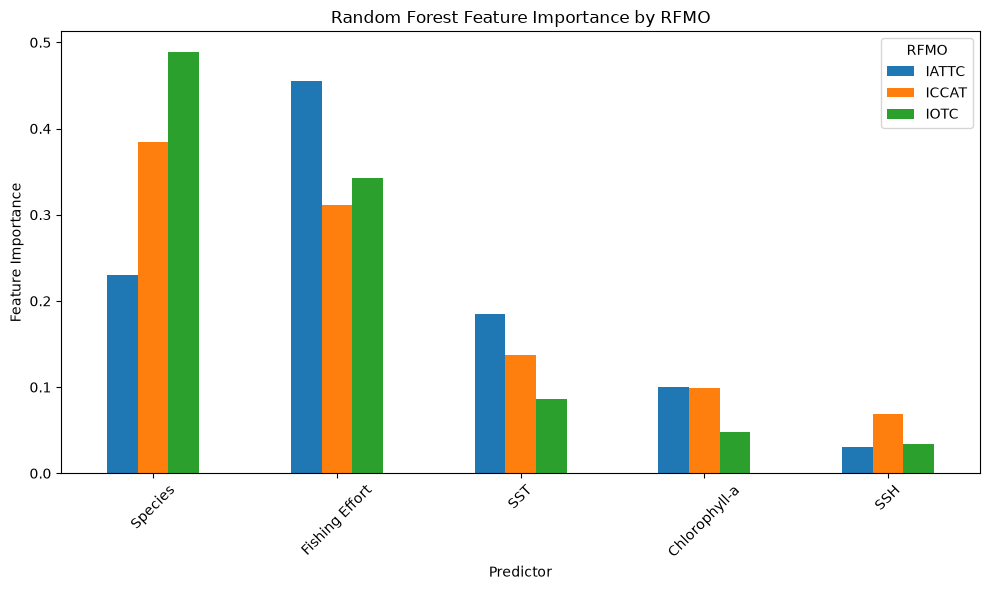

In [63]:
##Ground Bar Chart
import matplotlib.pyplot as plt

importance_pivot = importance_comparison.pivot(
    index="Predictor",
    columns="RFMO",
    values="Importance"
)

importance_pivot = importance_pivot.loc[
    ["Species", "Fishing Effort", "SST", "Chlorophyll-a", "SSH"]
]

importance_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Random Forest Feature Importance by RFMO")
plt.xlabel("Predictor")
plt.ylabel("Feature Importance")
plt.xticks(rotation=45)
plt.legend(title="RFMO")
plt.tight_layout()
plt.show()

### 7.2 Permutation Importance

Permutation importance is used as an additional model interpretation method to evaluate the contribution of each original predictor. Unlike impurity-based Random Forest feature importance, permutation importance measures the decrease in model performance when the values of a predictor are randomly shuffled.

This approach allows species, fishing effort and the environmental variables to be evaluated directly at the original predictor level without aggregating one-hot encoded species variables. Permutation importance is calculated using the test data to assess the contribution of each predictor to out-of-sample prediction.

In [64]:
from sklearn.inspection import permutation_importance

permutation_results = {}

for name, model in rf_models.items():

    X_test = splits[name]["X_test"]
    y_test = splits[name]["y_test"]

    perm = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="r2",
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    perm_df = pd.DataFrame({
        "Predictor": X_test.columns,
        "Importance": perm.importances_mean,
        "Std": perm.importances_std
    })

    # Rename predictors for readability
    perm_df["Predictor"] = perm_df["Predictor"].replace({
        "species_commonname": "Species",
        "mean_sst": "SST",
        "mean_chla": "Chlorophyll-a",
        "mean_ssh": "SSH",
        "original_effort": "Fishing Effort"
    })

    perm_df = perm_df.sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    permutation_results[name] = perm_df

    print(f"\n========== {name} ==========")
    display(perm_df.round(3))


========== ICCAT ==========


,Predictor,Importance,Std
0,Species,1.114,0.033
1,Fishing Effort,0.591,0.033
2,SST,0.198,0.009
3,Chlorophyll-a,0.076,0.005
4,SSH,0.009,0.003



========== IOTC ==========


,Predictor,Importance,Std
0,Species,1.394,0.051
1,Fishing Effort,0.620,0.029
2,SST,0.113,0.005
3,Chlorophyll-a,0.014,0.003
4,SSH,0.003,0.003



========== IATTC ==========


,Predictor,Importance,Std
0,Species,1.447,0.013
1,Fishing Effort,0.915,0.003
2,SST,0.586,0.004
3,Chlorophyll-a,0.259,0.002
4,SSH,0.007,0.000


In [65]:
# Combine permutation importance results
permutation_comparison = pd.DataFrame()

for name, perm_df in permutation_results.items():
    temp = perm_df.copy()
    temp["RFMO"] = name

    permutation_comparison = pd.concat(
        [permutation_comparison, temp],
        ignore_index=True
    )

display(permutation_comparison.round(3))

,Predictor,Importance,Std,RFMO
0,Species,1.114,0.033,ICCAT
1,Fishing Effort,0.591,0.033,ICCAT
2,SST,0.198,0.009,ICCAT
3,Chlorophyll-a,0.076,0.005,ICCAT
4,SSH,0.009,0.003,ICCAT
5,Species,1.394,0.051,IOTC
6,Fishing Effort,0.620,0.029,IOTC
7,SST,0.113,0.005,IOTC
8,Chlorophyll-a,0.014,0.003,IOTC
9,SSH,0.003,0.003,IOTC


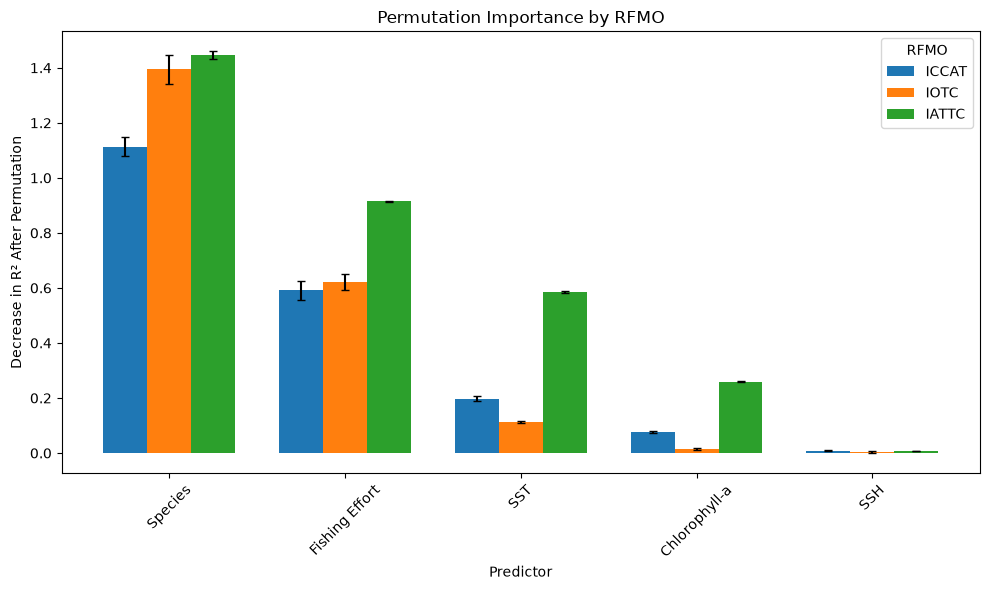

In [66]:
import matplotlib.pyplot as plt
import numpy as np

predictor_order = [
    "Species",
    "Fishing Effort",
    "SST",
    "Chlorophyll-a",
    "SSH"
]

rfmo_order = ["ICCAT", "IOTC", "IATTC"]

x = np.arange(len(predictor_order))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

for i, rfmo in enumerate(rfmo_order):

    subset = (
        permutation_comparison[
            permutation_comparison["RFMO"] == rfmo
        ]
        .set_index("Predictor")
        .reindex(predictor_order)
    )

    ax.bar(
        x + (i - 1) * width,
        subset["Importance"],
        width,
        yerr=subset["Std"],
        capsize=3,
        label=rfmo
    )

ax.set_title("Permutation Importance by RFMO")
ax.set_xlabel("Predictor")
ax.set_ylabel("Decrease in R² After Permutation")
ax.set_xticks(x)
ax.set_xticklabels(predictor_order, rotation=45)
ax.legend(title="RFMO")

plt.tight_layout()
plt.show()

Permutation importance broadly supports the findings of the impurity-based feature importance analysis. Shark species has the largest impact on predictive performance across all three RFMO models, followed by fishing effort.

Among the environmental predictors, SST consistently has the greatest permutation importance, followed by chlorophyll-a, while SSH provides relatively little additional predictive information. The contribution of environmental predictors is particularly pronounced in the IATTC model, where permutation of SST and chlorophyll-a results in substantially larger reductions in predictive performance than in ICCAT and IOTC.

Some differences are observed between the two feature importance methods. In particular, impurity-based importance identifies fishing effort as the most important predictor in IATTC, whereas permutation importance identifies species as having the largest effect on model performance. This difference reflects the different ways in which the two methods measure predictor importance.

Overall, the results indicate that species and fishing effort are important for predicting observed shark catch, while environmental variables provide additional predictive information, particularly SST. These importance measures describe predictive contribution and should not be interpreted as causal effects.

### 7.3 Predictor Effects

Feature importance identifies which predictors contribute to model performance, but it does not show the direction or shape of their relationships with predicted shark catch. Partial Dependence Plots (PDPs) are therefore used to examine how predictions change across the values of selected continuous predictors while averaging over the other variables in the dataset.

SST, chlorophyll-a and fishing effort are selected for further analysis because they provide the strongest predictive information among the continuous predictors. SSH is not examined further because permutation importance indicates that it provides little additional predictive information across the three RFMO models.

The resulting patterns represent modelled associations rather than causal effects.

#### 7.3.1 Sea Surface Temperature (SST)

Partial dependence is first examined for SST because it consistently shows the highest importance among the environmental predictors across the three RFMO models.

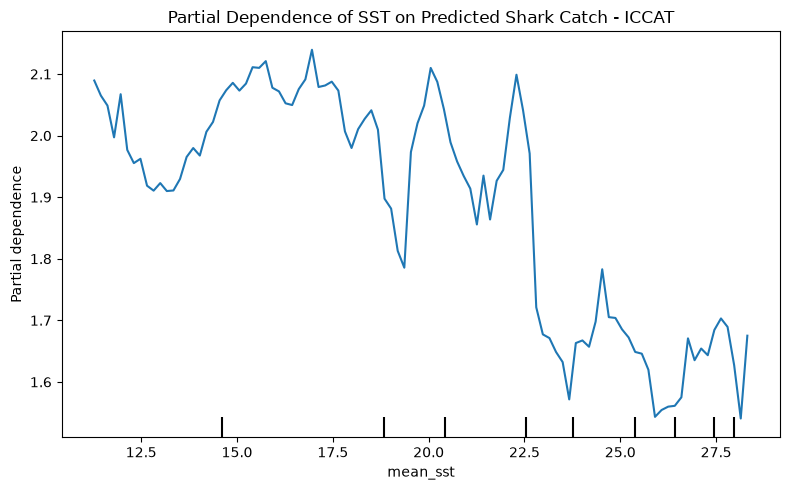

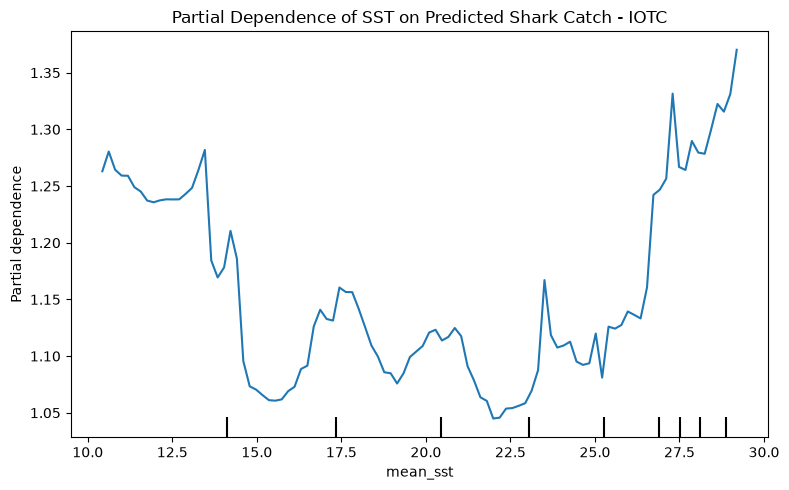

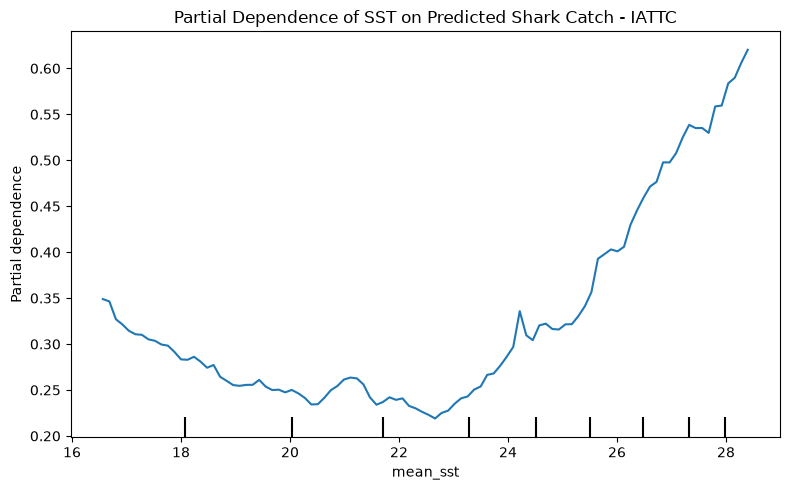

In [67]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

for name, model in rf_models.items():

    fig, ax = plt.subplots(figsize=(8, 5))

    PartialDependenceDisplay.from_estimator(
        model,
        splits[name]["X_test"],
        features=["mean_sst"],
        ax=ax
    )

    ax.set_title(f"Partial Dependence of SST on Predicted Shark Catch - {name}")
    ax.set_xlabel("Sea Surface Temperature (SST)")
    ax.set_ylabel("Partial Dependence (Log Catch)")

    plt.tight_layout()
    plt.show()

The partial dependence plots reveal substantial regional differences in the modelled relationship between SST and shark catch.

For ICCAT, the relationship is highly non-linear, with relatively higher predicted catch around 15–18°C followed by considerable variation and an overall decline at higher temperatures. In IOTC, predicted catch is relatively lower across much of the intermediate SST range but increases noticeably at higher temperatures, particularly above approximately 26°C.

The IATTC model shows the clearest temperature-related pattern. Predicted catch decreases from lower SST values towards approximately 22–23°C before increasing substantially at higher temperatures, particularly above approximately 25°C.

These regional differences support the use of separate RFMO models rather than assuming a single global SST–catch relationship. The patterns represent partial dependence in the fitted Random Forest models and should be interpreted as modelled associations rather than causal environmental effects.

#### 7.3.2 Chlorophyll-a

Partial dependence is examined for chlorophyll-a as the second most important environmental predictor identified by both feature importance methods.

Because chlorophyll-a contains several extreme values, the partial dependence analysis focuses on the central 5th–95th percentile range of the observed data. This reduces the influence of extreme observations and allows the modelled relationship across the main data range to be interpreted more clearly.

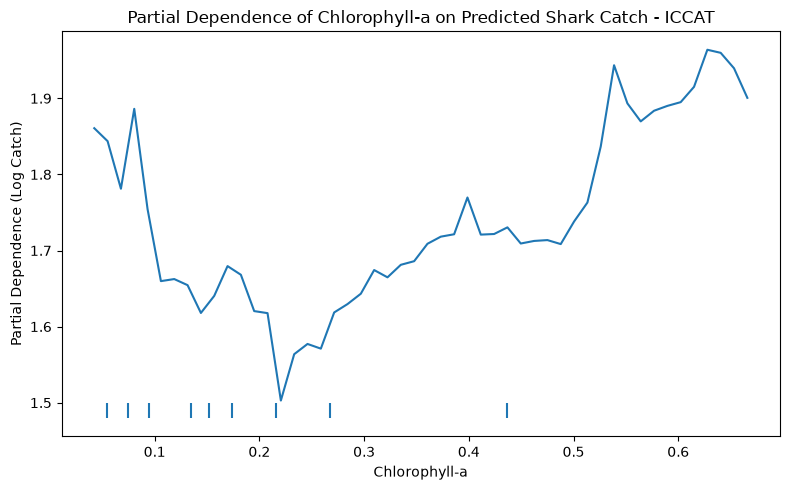

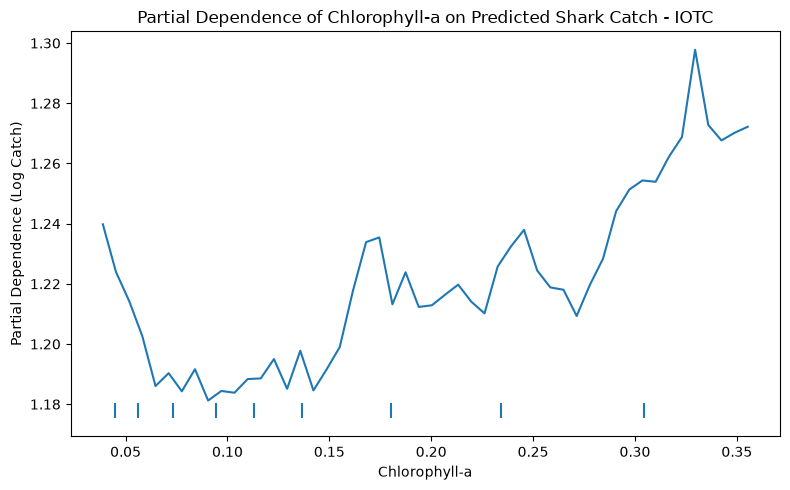

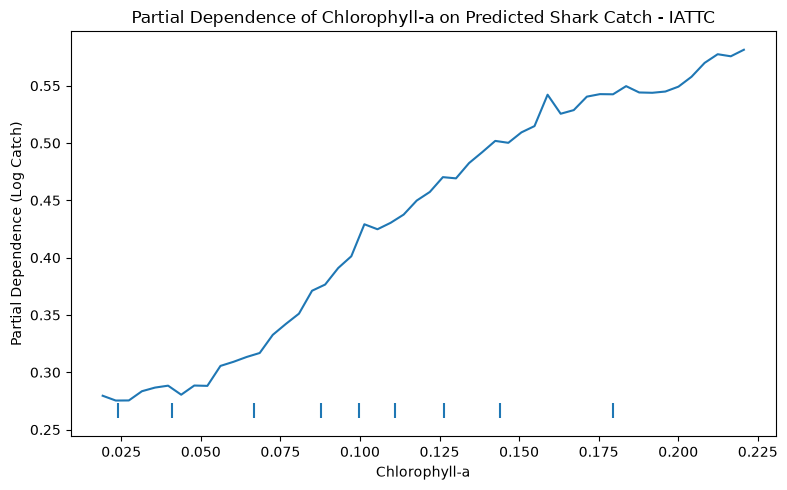

In [68]:
from sklearn.inspection import partial_dependence
import matplotlib.pyplot as plt
import numpy as np

for name, model in rf_models.items():

    # Copy test data for PDP calculation
    X_pdp = splits[name]["X_test"].copy()

    # Replace missing chlorophyll-a values with the median
    chla_median = X_pdp["mean_chla"].median()
    X_pdp["mean_chla"] = X_pdp["mean_chla"].fillna(chla_median)

    pd_result = partial_dependence(
        model,
        X_pdp,
        features=["mean_chla"],
        percentiles=(0.05, 0.95),
        grid_resolution=50
    )

    chla_values = pd_result["grid_values"][0]
    pd_values = pd_result["average"][0]

    plt.figure(figsize=(8, 5))

    plt.plot(chla_values, pd_values)

    # Add decile marks showing the observed data distribution
    deciles = np.percentile(
        X_pdp["mean_chla"],
        np.arange(10, 100, 10)
    )

    ymin, ymax = plt.ylim()

    plt.vlines(
        deciles,
        ymin,
        ymin + (ymax - ymin) * 0.04
    )

    plt.title(
        f"Partial Dependence of Chlorophyll-a on Predicted Shark Catch - {name}"
    )
    plt.xlabel("Chlorophyll-a")
    plt.ylabel("Partial Dependence (Log Catch)")

    plt.tight_layout()
    plt.show()

The partial dependence plots show that the modelled relationship between chlorophyll-a and shark catch differs across the three RFMOs.

In ICCAT, the relationship is strongly non-linear, with substantial variation at lower chlorophyll-a concentrations and generally higher predicted catch at higher concentrations. IOTC shows a weaker relationship, with predicted catch initially decreasing at low chlorophyll-a levels before gradually increasing across the higher range.

The clearest pattern is observed in IATTC, where predicted catch generally increases as chlorophyll-a concentration increases across the analysed range. This is consistent with the permutation importance results, which indicate a substantially greater predictive contribution of chlorophyll-a in IATTC than in ICCAT or IOTC.

Overall, chlorophyll-a provides region-specific predictive information rather than showing a consistent global relationship with shark catch. These patterns represent modelled associations and should not be interpreted as causal effects.

#### 7.3.3 Fishing Effort

Fishing effort is examined because it is one of the strongest predictors across all three RFMO models. Partial dependence is used to investigate whether the modelled relationship between fishing effort and predicted shark catch is linear or whether changes in predicted catch vary across different levels of fishing activity.

The analysis focuses on the central 5th–95th percentile range to reduce the visual influence of extreme effort values.

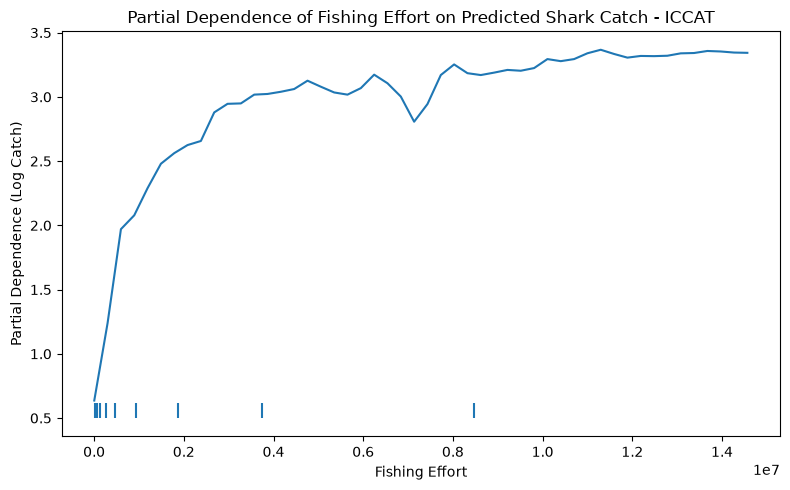

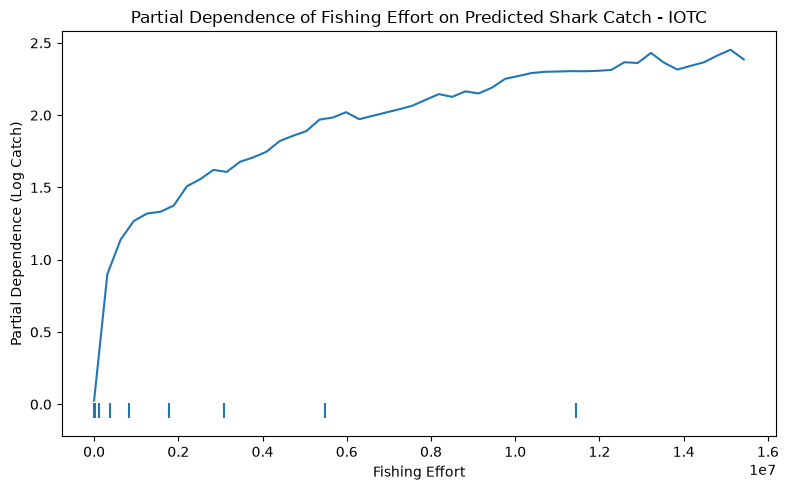

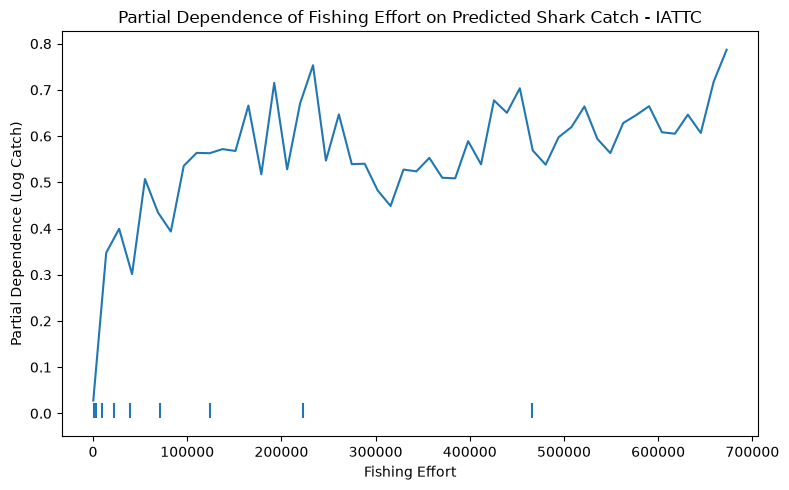

In [69]:
from sklearn.inspection import partial_dependence
import matplotlib.pyplot as plt
import numpy as np

for name, model in rf_models.items():

    X_pdp = splits[name]["X_test"].copy()

    # Apply median imputation to environmental predictors
    for col in ["mean_sst", "mean_chla", "mean_ssh"]:
        X_pdp[col] = X_pdp[col].fillna(
            X_pdp[col].median()
        )

    # Treat fishing effort as a continuous numeric variable for PDP
    X_pdp["original_effort"] = X_pdp["original_effort"].astype(float)

    pd_result = partial_dependence(
        model,
        X_pdp,
        features=["original_effort"],
        percentiles=(0.05, 0.95),
        grid_resolution=50
    )

    effort_values = pd_result["grid_values"][0]
    pd_values = pd_result["average"][0]

    plt.figure(figsize=(8, 5))

    plt.plot(
        effort_values,
        pd_values
    )

    # Show distribution of fishing effort
    deciles = np.percentile(
        X_pdp["original_effort"],
        np.arange(10, 100, 10)
    )

    ymin, ymax = plt.ylim()

    plt.vlines(
        deciles,
        ymin,
        ymin + (ymax - ymin) * 0.04
    )

    plt.title(
        f"Partial Dependence of Fishing Effort on Predicted Shark Catch - {name}"
    )
    plt.xlabel("Fishing Effort")
    plt.ylabel("Partial Dependence (Log Catch)")

    plt.tight_layout()
    plt.show()

Across all three RFMO models, fishing effort shows an overall positive but non-linear relationship with predicted shark catch.

In ICCAT and IOTC, predicted catch increases rapidly at lower levels of fishing effort before the rate of increase gradually slows at higher effort levels. This produces a flattening pattern rather than a simple linear relationship. IATTC also shows an overall positive relationship, although the modelled response contains greater local variation across the effort range.

These patterns are consistent with the earlier correlation analysis, where Spearman correlations between fishing effort and catch were stronger than Pearson correlations. This suggests that fishing effort has a broadly monotonic association with catch, while the relationship is not well represented by a simple linear trend.

Fishing effort therefore provides substantial predictive information across all three RFMO models. However, the partial dependence patterns represent modelled associations and should not be interpreted as evidence that increased fishing effort directly causes a proportional increase in shark catch.

## 8. Modelling Summary

### 8.1 Model Performance Summary

In [70]:
# Final model performance summary
final_model_summary = (
    model_comparison[
        model_comparison["Model"] == "Random Forest"
    ]
    .copy()
    .sort_values("RFMO")
    .reset_index(drop=True)
)

display(final_model_summary.round(3))

,RFMO,Model,MAE (Log),RMSE (Log),R² (Log),MAE (Original),RMSE (Original)
0,IATTC,Random Forest,0.118,0.362,0.885,2.160,16.516
1,ICCAT,Random Forest,0.923,1.519,0.655,211.531,984.780
2,IOTC,Random Forest,0.465,0.923,0.811,56.917,361.723


Three regression approaches were evaluated independently for each RFMO: Linear Regression, Random Forest and Gradient Boosting. Random Forest achieved the strongest predictive performance across ICCAT, IOTC and IATTC and was therefore selected as the final modelling approach.

On the log-transformed catch target, the Random Forest models achieved R² values of 0.655 for ICCAT, 0.811 for IOTC and 0.885 for IATTC. The results indicate that model performance varies across regions, with the IATTC model explaining the largest proportion of variation in log-transformed catch and the ICCAT model showing greater unexplained variation.

Original-scale MAE and RMSE are also reported to provide an indication of prediction error in the original catch units. However, these values should not be directly compared across RFMOs because the datasets have substantially different catch distributions and scales.

The use of separate RFMO models preserves regional differences in spatial resolution, species composition, environmental conditions and catch patterns rather than assuming a single global relationship.

## 8.2 Key Modelling Findings

The modelling and interpretation analyses produced several key findings:

- Species and fishing effort were the strongest overall predictors of observed shark catch across the three RFMO models.
- SST was the most consistently important environmental predictor, although its modelled relationship with catch differed substantially between regions.
- Chlorophyll-a provided additional region-specific predictive information, with a particularly strong contribution in the IATTC model.
- SSH showed limited additional predictive contribution across all three models.
- Partial dependence analysis showed that the relationships between shark catch and SST, chlorophyll-a and fishing effort were generally non-linear and region-specific.
- The differences in model performance and predictor-response patterns across ICCAT, IOTC and IATTC support the decision to maintain separate regional models.

Overall, the results demonstrate that observed shark catch patterns are associated with a combination of shark species, fishing activity and environmental conditions. The final Random Forest models provide the predictive component that can subsequently be integrated into the interactive dashboard.

These results describe predictive associations within the available fisheries datasets and should not be interpreted as causal relationships or direct estimates of shark abundance.